In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
# A fixed seed makes our random choices repeatable.
SEED = 42

In [6]:
iris = load_iris()
X = iris.data
y = iris.target

flowers = pd.DataFrame(X, columns=iris.feature_names)
flowers['species'] = iris.target_names[y]
print(flowers.head().to_string(index=False))
print('\nNumber of flowers:', len(X))
print('Missing measurements:', np.isnan(X).sum())
print('Species:', iris.target_names)

 sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm) species
               5.1               3.5                1.4               0.2  setosa
               4.9               3.0                1.4               0.2  setosa
               4.7               3.2                1.3               0.2  setosa
               4.6               3.1                1.5               0.2  setosa
               5.0               3.6                1.4               0.2  setosa

Number of flowers: 150
Missing measurements: 0
Species: ['setosa' 'versicolor' 'virginica']


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print('Flowers available for training and validation:', len(X_train))
print('Flowers reserved for the final test:', len(X_test))

Flowers available for training and validation: 120
Flowers reserved for the final test: 30


In [8]:
def evaluate_predictions(actual, predicted):
    accuracy = accuracy_score(actual, predicted)
    f1 = f1_score(actual, predicted, labels=[0, 1, 2],
                  average='macro', zero_division=0)
    return accuracy, f1



In [9]:
rng = np.random.default_rng(SEED)
number_of_flowers = len(X_train)
all_indices = np.arange(number_of_flowers)

sample_indices = rng.choice(all_indices, size=number_of_flowers, replace=True)
unique_indices = np.unique(sample_indices)
oob_indices = np.setdiff1d(all_indices, unique_indices)

print('First 20 sampled row numbers:', sample_indices[:20])
print('Total draws:', len(sample_indices))
print('Different flowers selected:', len(unique_indices))
print('Flowers left for OOB evaluation:', len(oob_indices))


First 20 sampled row numbers: [ 10  92  78  52  51 103  10  83  24  11  63 117  88  91  86  94  61  15
 100  54]
Total draws: 120
Different flowers selected: 79
Flowers left for OOB evaluation: 41


In [10]:

rng = np.random.default_rng(SEED)
bootstrap_accuracy = []
bootstrap_f1 = []

for repetition in range(100):
    sample_indices = rng.choice(all_indices, size=number_of_flowers, replace=True)
    oob_indices = np.setdiff1d(all_indices, np.unique(sample_indices))

    # An empty OOB set cannot be evaluated.
    if len(oob_indices) == 0:
        continue

    model = DecisionTreeClassifier(max_depth=3, random_state=SEED)
    model.fit(X_train[sample_indices], y_train[sample_indices])
    predictions = model.predict(X_train[oob_indices])
    accuracy, f1 = evaluate_predictions(y_train[oob_indices], predictions)

    bootstrap_accuracy.append(accuracy)
    bootstrap_f1.append(f1)

print('Bootstrap repetitions evaluated:', len(bootstrap_accuracy))
print('Mean accuracy:', round(np.mean(bootstrap_accuracy), 4))
print('Mean macro F1:', round(np.mean(bootstrap_f1), 4))


Bootstrap repetitions evaluated: 100
Mean accuracy: 0.9441
Mean macro F1: 0.9426


In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_accuracy = []
cv_f1 = []

for fold, (fit_indices, validation_indices) in enumerate(cv.split(X_train, y_train), start=1):
    model = DecisionTreeClassifier(max_depth=3, random_state=SEED)
    model.fit(X_train[fit_indices], y_train[fit_indices])
    predictions = model.predict(X_train[validation_indices])
    accuracy, f1 = evaluate_predictions(y_train[validation_indices], predictions)

    cv_accuracy.append(accuracy)
    cv_f1.append(f1)
    print(f'Fold {fold}: accuracy = {accuracy:.4f}, macro F1 = {f1:.4f}')


Fold 1: accuracy = 0.9583, macro F1 = 0.9582
Fold 2: accuracy = 1.0000, macro F1 = 1.0000
Fold 3: accuracy = 0.9583, macro F1 = 0.9582
Fold 4: accuracy = 0.9583, macro F1 = 0.9582
Fold 5: accuracy = 0.9167, macro F1 = 0.9153


                 Method  Mean accuracy  Accuracy SD  Mean macro F1  Macro F1 SD
          Bootstrap OOB         0.9441       0.0330         0.9426       0.0337
5-fold cross-validation         0.9583       0.0295         0.9580       0.0299


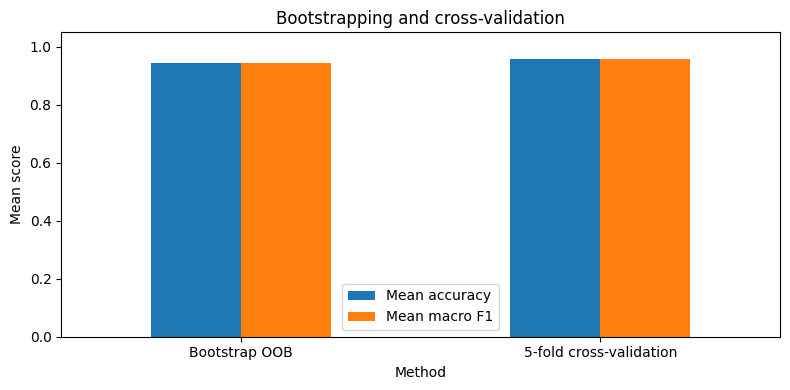

In [12]:
resampling_table = pd.DataFrame({
    'Method': ['Bootstrap OOB', '5-fold cross-validation'],
    'Mean accuracy': [np.mean(bootstrap_accuracy), np.mean(cv_accuracy)],
    'Accuracy SD': [np.std(bootstrap_accuracy, ddof=1), np.std(cv_accuracy, ddof=1)],
    'Mean macro F1': [np.mean(bootstrap_f1), np.mean(cv_f1)],
    'Macro F1 SD': [np.std(bootstrap_f1, ddof=1), np.std(cv_f1, ddof=1)]
})
print(resampling_table.round(4).to_string(index=False))

resampling_table.plot(x='Method', y=['Mean accuracy', 'Mean macro F1'],
                      kind='bar', ylim=(0, 1.05), rot=0, figsize=(8, 4))
plt.ylabel('Mean score')
plt.title('Bootstrapping and cross-validation')
plt.tight_layout()
plt.show()


In [13]:
depths = range(1, 11)
training_errors = []
validation_errors = []

for depth in depths:
    fold_training_errors = []
    fold_validation_errors = []

    for fit_indices, validation_indices in cv.split(X_train, y_train):
        model = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
        model.fit(X_train[fit_indices], y_train[fit_indices])

        training_predictions = model.predict(X_train[fit_indices])
        validation_predictions = model.predict(X_train[validation_indices])
        train_error = 1 - accuracy_score(y_train[fit_indices], training_predictions)
        validation_error = 1 - accuracy_score(y_train[validation_indices], validation_predictions)

        fold_training_errors.append(train_error)
        fold_validation_errors.append(validation_error)

    training_errors.append(np.mean(fold_training_errors))
    validation_errors.append(np.mean(fold_validation_errors))

# argmin gives the position of the smallest validation error.
# Adding 1 converts that position (starting at 0) to a depth (starting at 1).
best_depth = int(np.argmin(validation_errors)) + 1
print('Selected maximum depth:', best_depth)
print(pd.DataFrame({'Depth': list(depths), 'Training error': training_errors,
                    'Validation error': validation_errors}).round(4).to_string(index=False))


Selected maximum depth: 3
 Depth  Training error  Validation error
     1          0.3333            0.3333
     2          0.0333            0.0583
     3          0.0208            0.0417
     4          0.0062            0.0583
     5          0.0021            0.0500
     6          0.0000            0.0500
     7          0.0000            0.0500
     8          0.0000            0.0500
     9          0.0000            0.0500
    10          0.0000            0.0500


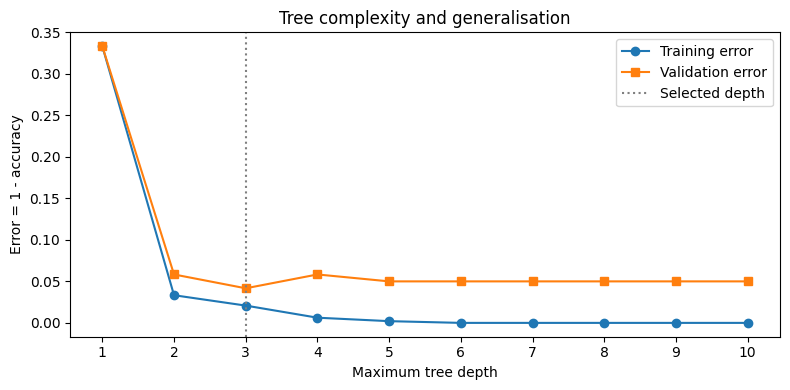

In [14]:
plt.figure(figsize=(8, 4))
plt.plot(depths, training_errors, 'o-', label='Training error')
plt.plot(depths, validation_errors, 's-', label='Validation error')
plt.axvline(best_depth, color='grey', linestyle=':', label='Selected depth')
plt.xticks(list(depths))
plt.xlabel('Maximum tree depth')
plt.ylabel('Error = 1 - accuracy')
plt.title('Tree complexity and generalisation')
plt.legend()
plt.tight_layout()
plt.show()


In [15]:
single_tree = DecisionTreeClassifier(random_state=SEED)

bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=SEED),
    n_estimators=100,
    random_state=SEED
)

boosting = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=SEED),
    n_estimators=100,
    learning_rate=0.5,
    random_state=SEED
)

selected_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=SEED)

single_tree.fit(X_train, y_train)
bagging.fit(X_train, y_train)
boosting.fit(X_train, y_train)
selected_tree.fit(X_train, y_train)
print('All four models have been trained.')


All four models have been trained.


In [17]:
model_names = ['Single tree', 'Bagging', 'AdaBoost', 'CV-selected tree']
trained_models = [single_tree, bagging, boosting, selected_tree]
results = []

for name, model in zip(model_names, trained_models):
    predictions = model.predict(X_test)
    accuracy, f1 = evaluate_predictions(y_test, predictions)
    precision = precision_score(y_test, predictions, labels=[0, 1, 2],
                                average='macro', zero_division=0)
    recall = recall_score(y_test, predictions, labels=[0, 1, 2],
                          average='macro', zero_division=0)
    results.append([name, accuracy, precision, recall, f1])

test_table = pd.DataFrame(results, columns=[
    'Model', 'Accuracy', 'Macro precision', 'Macro recall', 'Macro F1'
])
print(test_table.round(4).to_string(index=False))


           Model  Accuracy  Macro precision  Macro recall  Macro F1
     Single tree    0.9333           0.9333        0.9333    0.9333
         Bagging    0.9667           0.9697        0.9667    0.9666
        AdaBoost    0.9667           0.9697        0.9667    0.9666
CV-selected tree    0.9667           0.9697        0.9667    0.9666


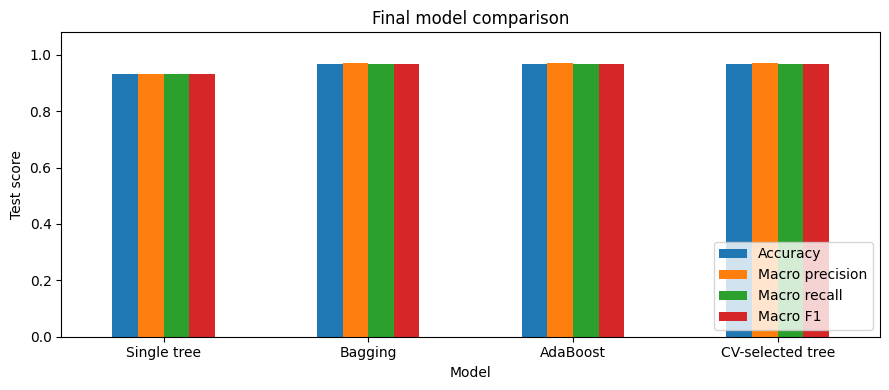

In [18]:
test_table.plot(x='Model', y=['Accuracy', 'Macro precision', 'Macro recall', 'Macro F1'],
                kind='bar', figsize=(9, 4), rot=0, ylim=(0, 1.08))
plt.ylabel('Test score')
plt.title('Final model comparison')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()
